# PhishGuard AI — read-only dataset validation

This notebook audits `model/Data/phishing_features.csv` without changing it. It does not clean or transform the source, remove rows, impute values, rebalance classes, split data, evaluate a predictive model, or train anything. The reproducible analysis implementation is in the adjacent `eda_analysis.py`; this notebook runs it and displays the generated evidence and visualizations.

Run all cells from top to bottom. The Public Suffix List snapshot in this folder is used only for PSL-aware registrable-domain grouping.

In [1]:
import sys
from pathlib import Path
from IPython.display import display, Image

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (parent for parent in (cwd, *cwd.parents)
     if (parent / "model" / "Data" / "phishing_features.csv").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate model/Data/phishing_features.csv from the current directory")
EDA_DIR = PROJECT_ROOT / "model" / "EDA"
if str(EDA_DIR) not in sys.path:
    sys.path.insert(0, str(EDA_DIR))

from eda_analysis import run_eda

results = run_eda()
print("Read-only analysis completed. No preprocessing or model evaluation was run.")

Read-only analysis completed. No preprocessing or model evaluation was run.


## Dataset integrity, types, missingness and labels

The overview includes the source-file SHA-256, deep memory estimate, row/column counts and exact duplicate checks. The label meanings shown below are project-documented claims; upstream provenance is unresolved.

In [2]:
display(results["overview"])
display(results["dtypes_missing"])
display(results["label_counts"])
display(results["missing_by_label"])


,measure,value
0,rows,160064
1,columns,13
2,memory_usage_bytes_deep,41561450
3,duplicate_rows,0
4,exact_duplicate_urls,0
5,blank_or_whitespace_urls,0
6,dataset_sha256,1de48e23501c544b6d345fcdeca544c42f71ab10d3061e...
7,psl_version,2026-11-11_17-18-20_UTC
8,psl_exact_rules,10097
9,psl_wildcard_rules,314


,column,dtype,missing,unique_including_missing
0,url,str,0,160064
1,label,int64,0,2
2,url_length,int64,0,521
3,num_dots,int64,0,19
4,has_https,int64,0,2
5,has_ip,int64,0,2
6,num_subdirs,int64,0,24
7,num_params,int64,0,23
8,suspicious_words,int64,0,4
9,tld,str,821,536


,label,rows,percent,meaning_in_project_docs
0,0,820,0.512295,LEGITIMATE (project-documented)
1,1,159244,99.487705,PHISHING (project-documented)


,label,rows,missing_tld,missing_tld_percent
0,0,820,820,100.000000
1,1,159244,1,0.000628


## URL parsing, structure and Public Suffix List domains

Scheme-less values are parsed as authorities for inspection. This does not establish DNS validity or reachability. Normalized URLs are diagnostic keys only; the raw URL column remains unchanged. The scheme-ignored key is intentionally broad and is not a deduplication rule.

In [3]:
print("URL parse statuses by label")
display(results["parse_status"])
print("URL components by label and scheme")
display(results["url_structure"])
print("Normalized URL collision counts")
display(results["normalized_duplicates"])
print("Registrable-domain overlap; illustrative random 80/20 split risk")
display(results["domain_summary"])
display(results["mixed_domains"])
print("Repeated host/path templates (heuristic candidates, not proven duplicates)")
display(results["template_summary"])
display(results["template_examples"])


URL parse statuses by label


,label,parse_status,rows
0,0,ok,820
1,1,ok,159244


URL components by label and scheme


,label,scheme,rows,path_present,query_present,fragment_present,mean_path_segments,path_present_percent,query_present_percent,fragment_present_percent
0,0,NO_SCHEME,820,0,0,0,0.000000,0.000000,0.000000,0.000000
1,1,http,89762,89094,544,16,2.260589,99.255810,0.606047,0.017825
2,1,https,69482,68637,15229,340,1.723482,98.783858,21.917907,0.489335


Normalized URL collision counts


,normalization,duplicate_rows_after_first,duplicate_groups,mixed_label_groups
0,scheme-preserving (host case/IDNA/trailing dot...,93,93,0
1,same key while ignoring scheme (diagnostic only),629,621,0


... (2 outputs left out)

,registrable_domain,rows,label_count,labels
0,google.com,7699,2,"{""1"": 7695, ""0"": 4}"
1,github.com,1598,2,"{""1"": 1597, ""0"": 1}"
2,adobe.com,1107,2,"{""1"": 1106, ""0"": 1}"
3,dropbox.com,645,2,"{""1"": 644, ""0"": 1}"
4,archive.org,72,2,"{""1"": 71, ""0"": 1}"
5,evernote.com,57,2,"{""1"": 56, ""0"": 1}"
6,zoom.us,56,2,"{""1"": 55, ""0"": 1}"
7,bitbucket.org,56,2,"{""1"": 55, ""0"": 1}"
8,bing.com,39,2,"{""1"": 38, ""0"": 1}"
9,booking.com,35,2,"{""1"": 34, ""0"": 1}"


Repeated host/path templates (heuristic candidates, not proven duplicates)


,measure,value
0,repeated host/path templates,6515
1,rows in repeated templates,23395
2,templates containing both labels,0


,template,rows,label_count
0,201.16.194.227/TmpFTP/EXTCONS/1/<NUM>/<HEX>/in...,1227,1
1,177.70.102.232/TmpFTP/TD<NUM>/info.zip?,565,1
2,200.14.250.72/TmpFTP/DELCACHEPRODUTOSEG/1/<NUM...,461,1
3,177.70.102.228/TmpFTP/TD<NUM>/info.zip?,394,1
4,img1.wsimg.com/blobby/go/<UUID>/downloads/<NUM...,381,1
5,drive.google.com/uc?export&id,261,1
6,l.wl.co/l?u,253,1
7,eu.jotform.com/app/<HEX>?,214,1
8,app.jotform.com/<HEX>?,168,1
9,201.16.194.227/TmpFTP/DELCACHEPRODUTOSEG/1/<NU...,116,1


## Feature distributions, class comparison and outliers

IQR flags are descriptive only. No rows are removed. Numerical summaries omit the target label; per-feature top values include missing values explicitly.

In [4]:
display(results["feature_summary"])
display(results["feature_distributions"])
display(results["numeric_statistics"])
display(results["feature_by_label"])
display(results["outliers"])


,feature,dtype,unique_including_missing,missing,dominant_value,dominant_percent,top_values_and_counts
0,url_length,int64,521,0,34,5.5715,34: 8918; 33: 8248; 28: 8170; 29: 7953; 35: 61...
1,num_dots,int64,19,0,4,34.1813,4: 54712; 3: 48173; 2: 39331; 1: 13783; 5: 227...
2,has_https,int64,2,0,0,56.5911,0: 90582; 1: 69482
3,has_ip,int64,2,0,0,51.4525,0: 82357; 1: 77707
4,num_subdirs,int64,24,0,3,60.4240,3: 96717; 4: 24865; 7: 11346; 8: 6636; 5: 6372...
5,num_params,int64,23,0,0,90.1127,0: 144238; 1: 7523; 3: 4260; 2: 1957; 4: 1515;...
6,suspicious_words,int64,4,0,0,97.8671,0: 156650; 1: 3025; 2: 381; 3: 8
7,tld,str,536,821,com,20.2050,com: 32341; ru: 15011; 202: 3745; 34: 3551; 22...
8,special_char_count,int64,74,0,0,61.6585,0: 98693; 1: 25591; 2: 10441; 4: 4709; 3: 4089...
9,digits_count,int64,180,0,0,12.8224,0: 20524; 15: 13721; 16: 12336; 1: 9833; 14: 8...


,feature,unique_including_missing,top_values_and_counts
0,url_length,521,34: 8918; 33: 8248; 28: 8170; 29: 7953; 35: 61...
1,num_dots,19,4: 54712; 3: 48173; 2: 39331; 1: 13783; 5: 227...
2,has_https,2,0: 90582; 1: 69482
3,has_ip,2,0: 82357; 1: 77707
4,num_subdirs,24,3: 96717; 4: 24865; 7: 11346; 8: 6636; 5: 6372...
5,num_params,23,0: 144238; 1: 7523; 3: 4260; 2: 1957; 4: 1515;...
6,suspicious_words,4,0: 156650; 1: 3025; 2: 381; 3: 8
7,tld,536,com: 32341; ru: 15011; 202: 3745; 34: 3551; 22...
8,special_char_count,74,0: 98693; 1: 25591; 2: 10441; 4: 4709; 3: 4089...
9,digits_count,180,0: 20524; 15: 13721; 16: 12336; 1: 9833; 14: 8...


,feature,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
0,url_length,160064.0,55.107382,101.782469,6.000000,21.000000,30.000000,37.000000,65.00000,155.000000,190.000000,25523.000000
1,num_dots,160064.0,2.998963,1.119210,1.000000,1.000000,2.000000,3.000000,4.00000,4.000000,6.000000,59.000000
2,has_https,160064.0,0.434089,0.495638,0.000000,0.000000,0.000000,0.000000,1.00000,1.000000,1.000000,1.000000
3,has_ip,160064.0,0.485475,0.499791,0.000000,0.000000,0.000000,0.000000,1.00000,1.000000,1.000000,1.000000
4,num_subdirs,160064.0,4.128436,2.090180,0.000000,2.000000,3.000000,3.000000,4.00000,8.000000,11.000000,104.000000
5,num_params,160064.0,0.221499,0.935608,0.000000,0.000000,0.000000,0.000000,0.00000,2.000000,4.000000,45.000000
6,suspicious_words,160064.0,0.023809,0.168235,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,1.000000,3.000000
7,special_char_count,160064.0,1.495446,3.699627,0.000000,0.000000,0.000000,0.000000,1.00000,8.000000,17.000000,264.000000
8,digits_count,160064.0,12.737036,17.420579,0.000000,0.000000,3.000000,12.000000,16.00000,35.000000,51.370000,3413.000000
9,entropy,160064.0,4.246100,0.479275,2.058814,3.453531,3.907734,4.171465,4.48485,5.193983,5.612705,6.030422


,label,url_length_mean,url_length_median,url_length_min,url_length_max,num_dots_mean,num_dots_median,num_dots_min,num_dots_max,has_https_mean,...,special_char_count_min,special_char_count_max,digits_count_mean,digits_count_median,digits_count_min,digits_count_max,entropy_mean,entropy_median,entropy_min,entropy_max
0,0,14.0780,16.0,6,22,1.0354,1.0,1,2,0.0000,...,0,1,1.0866,1.0,0,3,3.3554,3.4548,2.0588,3.9698
1,1,55.3187,37.0,12,25523,3.0091,3.0,1,59,0.4363,...,0,264,12.7970,12.0,0,3413,4.2507,4.1751,2.3533,6.0304


,feature,q1,median,q3,p99,max,iqr_lower,iqr_upper,iqr_outlier_rows,iqr_outlier_percent
0,url_length,30.000000,37.000000,65.00000,190.000000,25523.000000,-22.50000,117.500000,12907,8.063650
1,num_dots,2.000000,3.000000,4.00000,6.000000,59.000000,-1.00000,7.000000,331,0.206792
2,has_https,0.000000,0.000000,1.00000,1.000000,1.000000,-1.50000,2.500000,0,0.000000
3,has_ip,0.000000,0.000000,1.00000,1.000000,1.000000,-1.50000,2.500000,0,0.000000
4,num_subdirs,3.000000,3.000000,4.00000,11.000000,104.000000,1.50000,5.500000,30597,19.115479
5,num_params,0.000000,0.000000,0.00000,4.000000,45.000000,0.00000,0.000000,15826,9.887295
6,suspicious_words,0.000000,0.000000,0.00000,1.000000,3.000000,0.00000,0.000000,3414,2.132897
7,special_char_count,0.000000,0.000000,1.00000,17.000000,264.000000,-1.50000,2.500000,25339,15.830543
8,digits_count,3.000000,12.000000,16.00000,51.370000,3413.000000,-16.50000,35.500000,7199,4.497576
9,entropy,3.907734,4.171465,4.48485,5.612705,6.030422,3.04206,5.350524,6375,3.982782


## Feature implementation consistency and association

Stored engineered values are compared against the currently committed feature extractor using the raw URL. A mismatch indicates a definition or implementation discrepancy; it does not identify which historical formula is correct. Correlation is descriptive and is not, alone, proof of target leakage.

In [5]:
display(results["feature_mismatches"])
display(results["tld_summary"])
display(results["correlation_pairs"])
display(results["spearman_label"])


,feature,mismatches,mismatch_percent
0,url_length,0,0.0000
1,num_dots,0,0.0000
2,has_https,0,0.0000
3,has_ip,109,0.0681
4,num_subdirs,0,0.0000
5,num_params,347,0.2168
6,suspicious_words,878,0.5485
7,tld,78447,49.0098
8,special_char_count,16139,10.0828
9,digits_count,0,0.0000


,measure,value
0,distinct stored TLD values including missing,536
1,rows with numeric stored TLD,77600
2,distinct numeric stored TLD values,256
3,rows with actual IP hostname,77598


,feature_a,feature_b,pearson_r
0,url_length,digits_count,0.825484
1,has_https,has_ip,-0.782388


,feature,spearman_with_label
4,num_subdirs,0.140450
0,url_length,0.123660
1,num_dots,0.117073
9,entropy,0.113320
8,digits_count,0.088311
3,has_ip,0.069704
2,has_https,0.062848
7,special_char_count,0.054082
5,num_params,0.023732
6,suspicious_words,0.008781


## Visual evidence

The TLD comparison uses separate within-class percentages, so the 194:1 class-size imbalance does not cause bar overlap or make the minority class invisible. It is explicitly a distribution of the stored `tld` field, which contains missing and numeric entries and is not yet a trustworthy TLD feature.

label_distribution.png


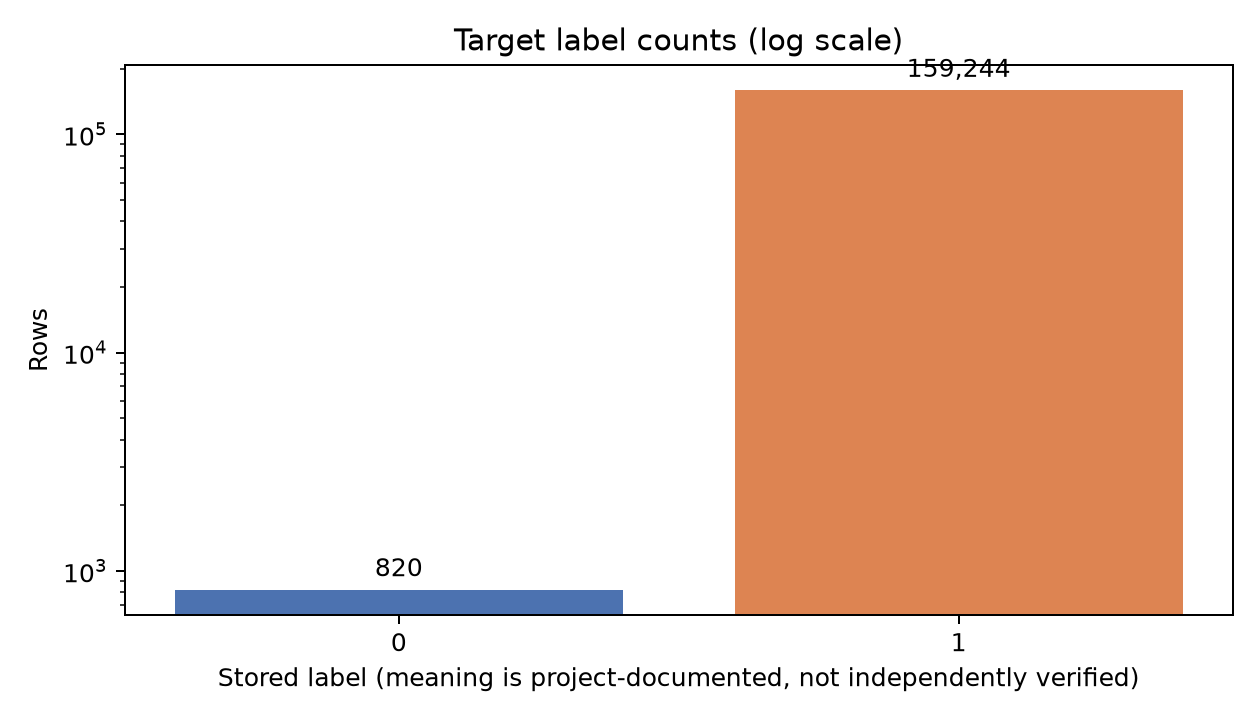

url_structure_by_label.png


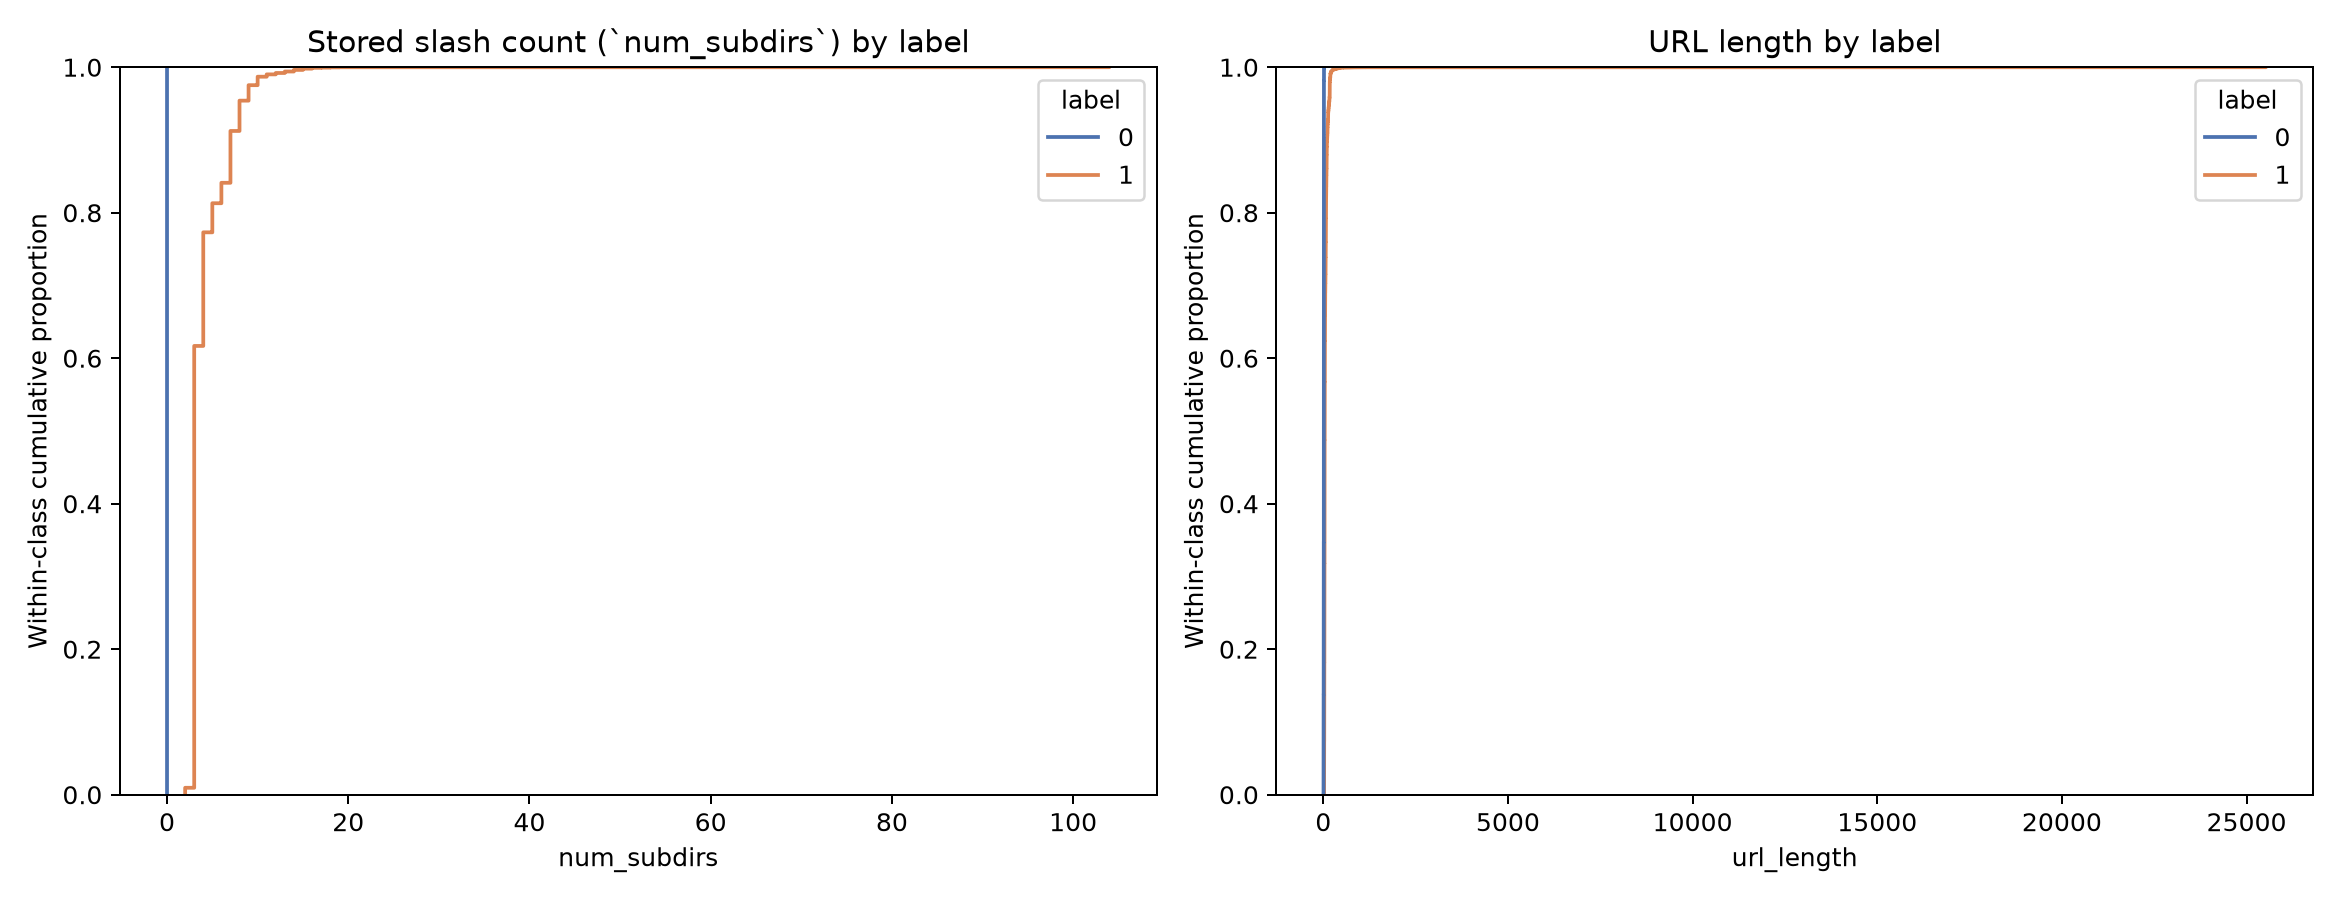

structure_by_label.png


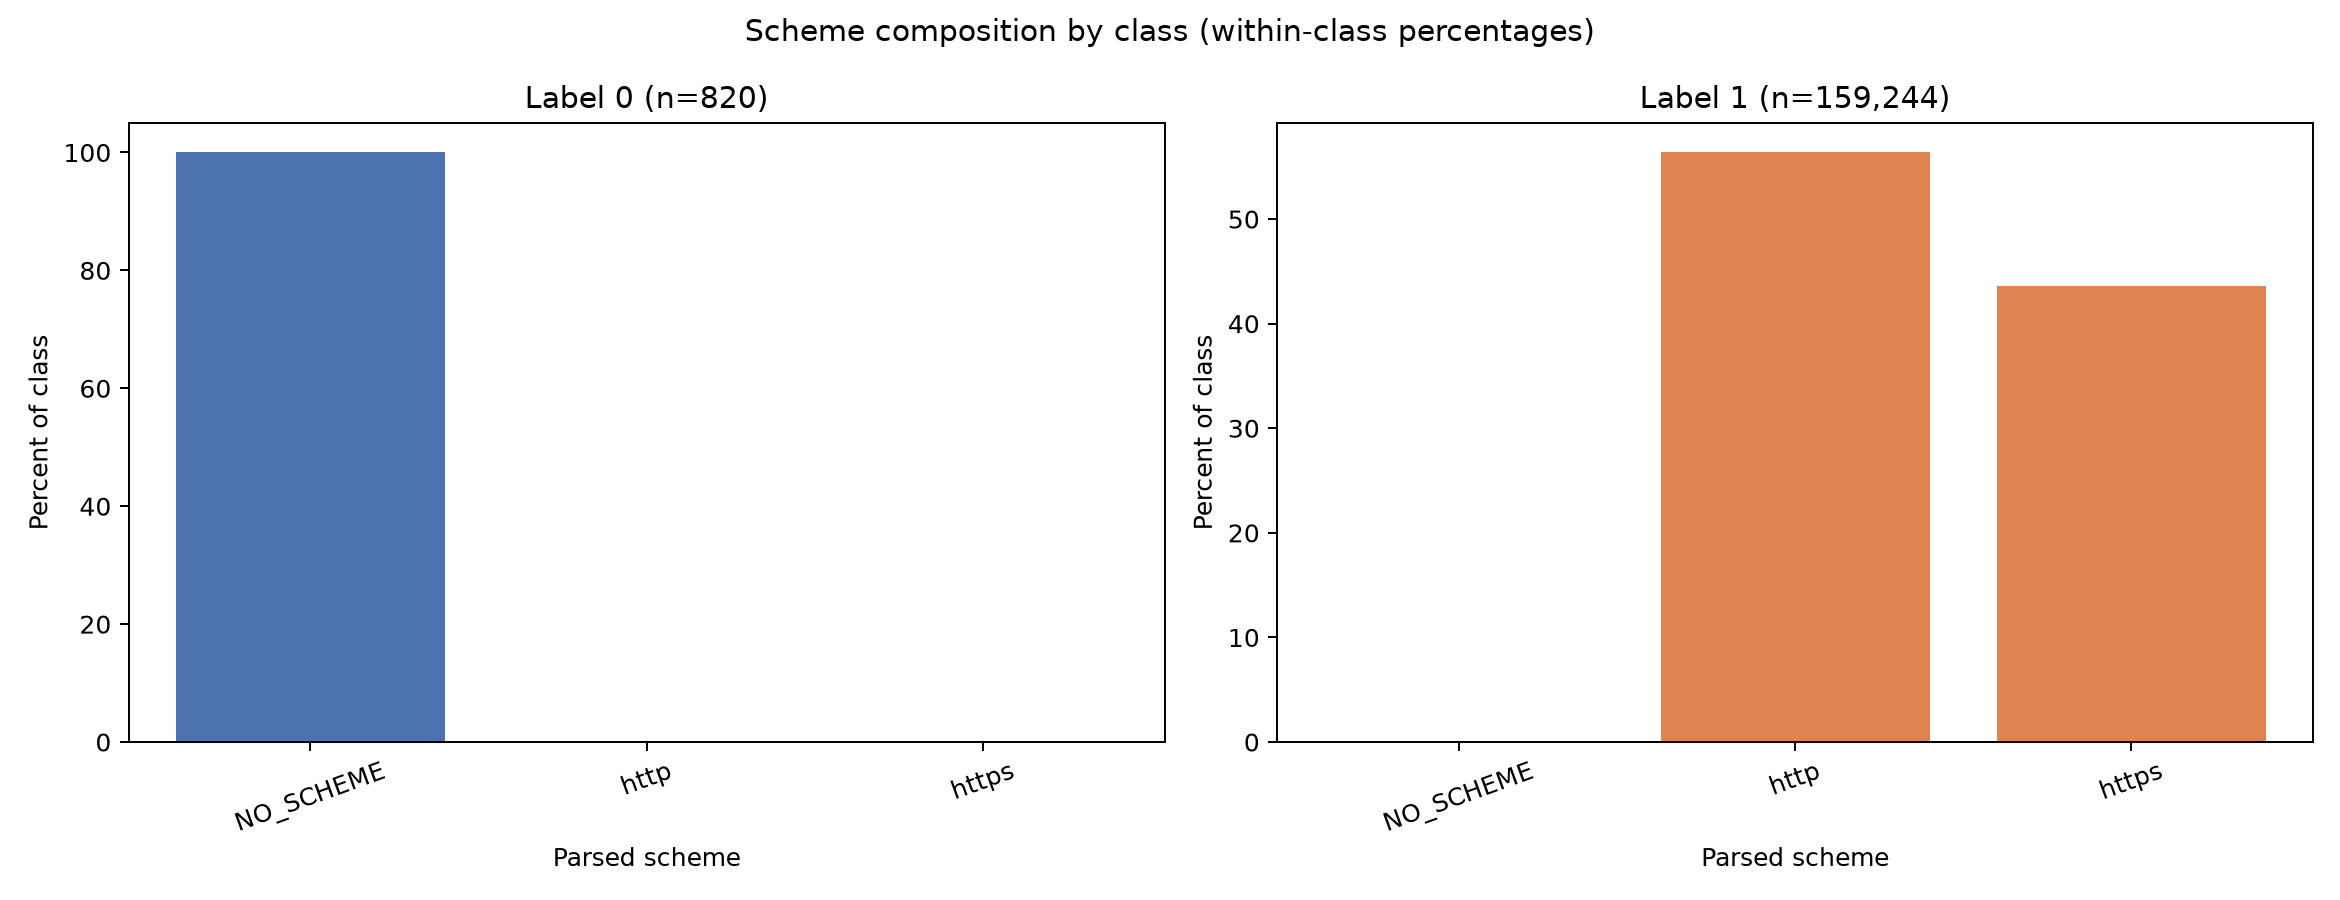

numeric_feature_histograms.png


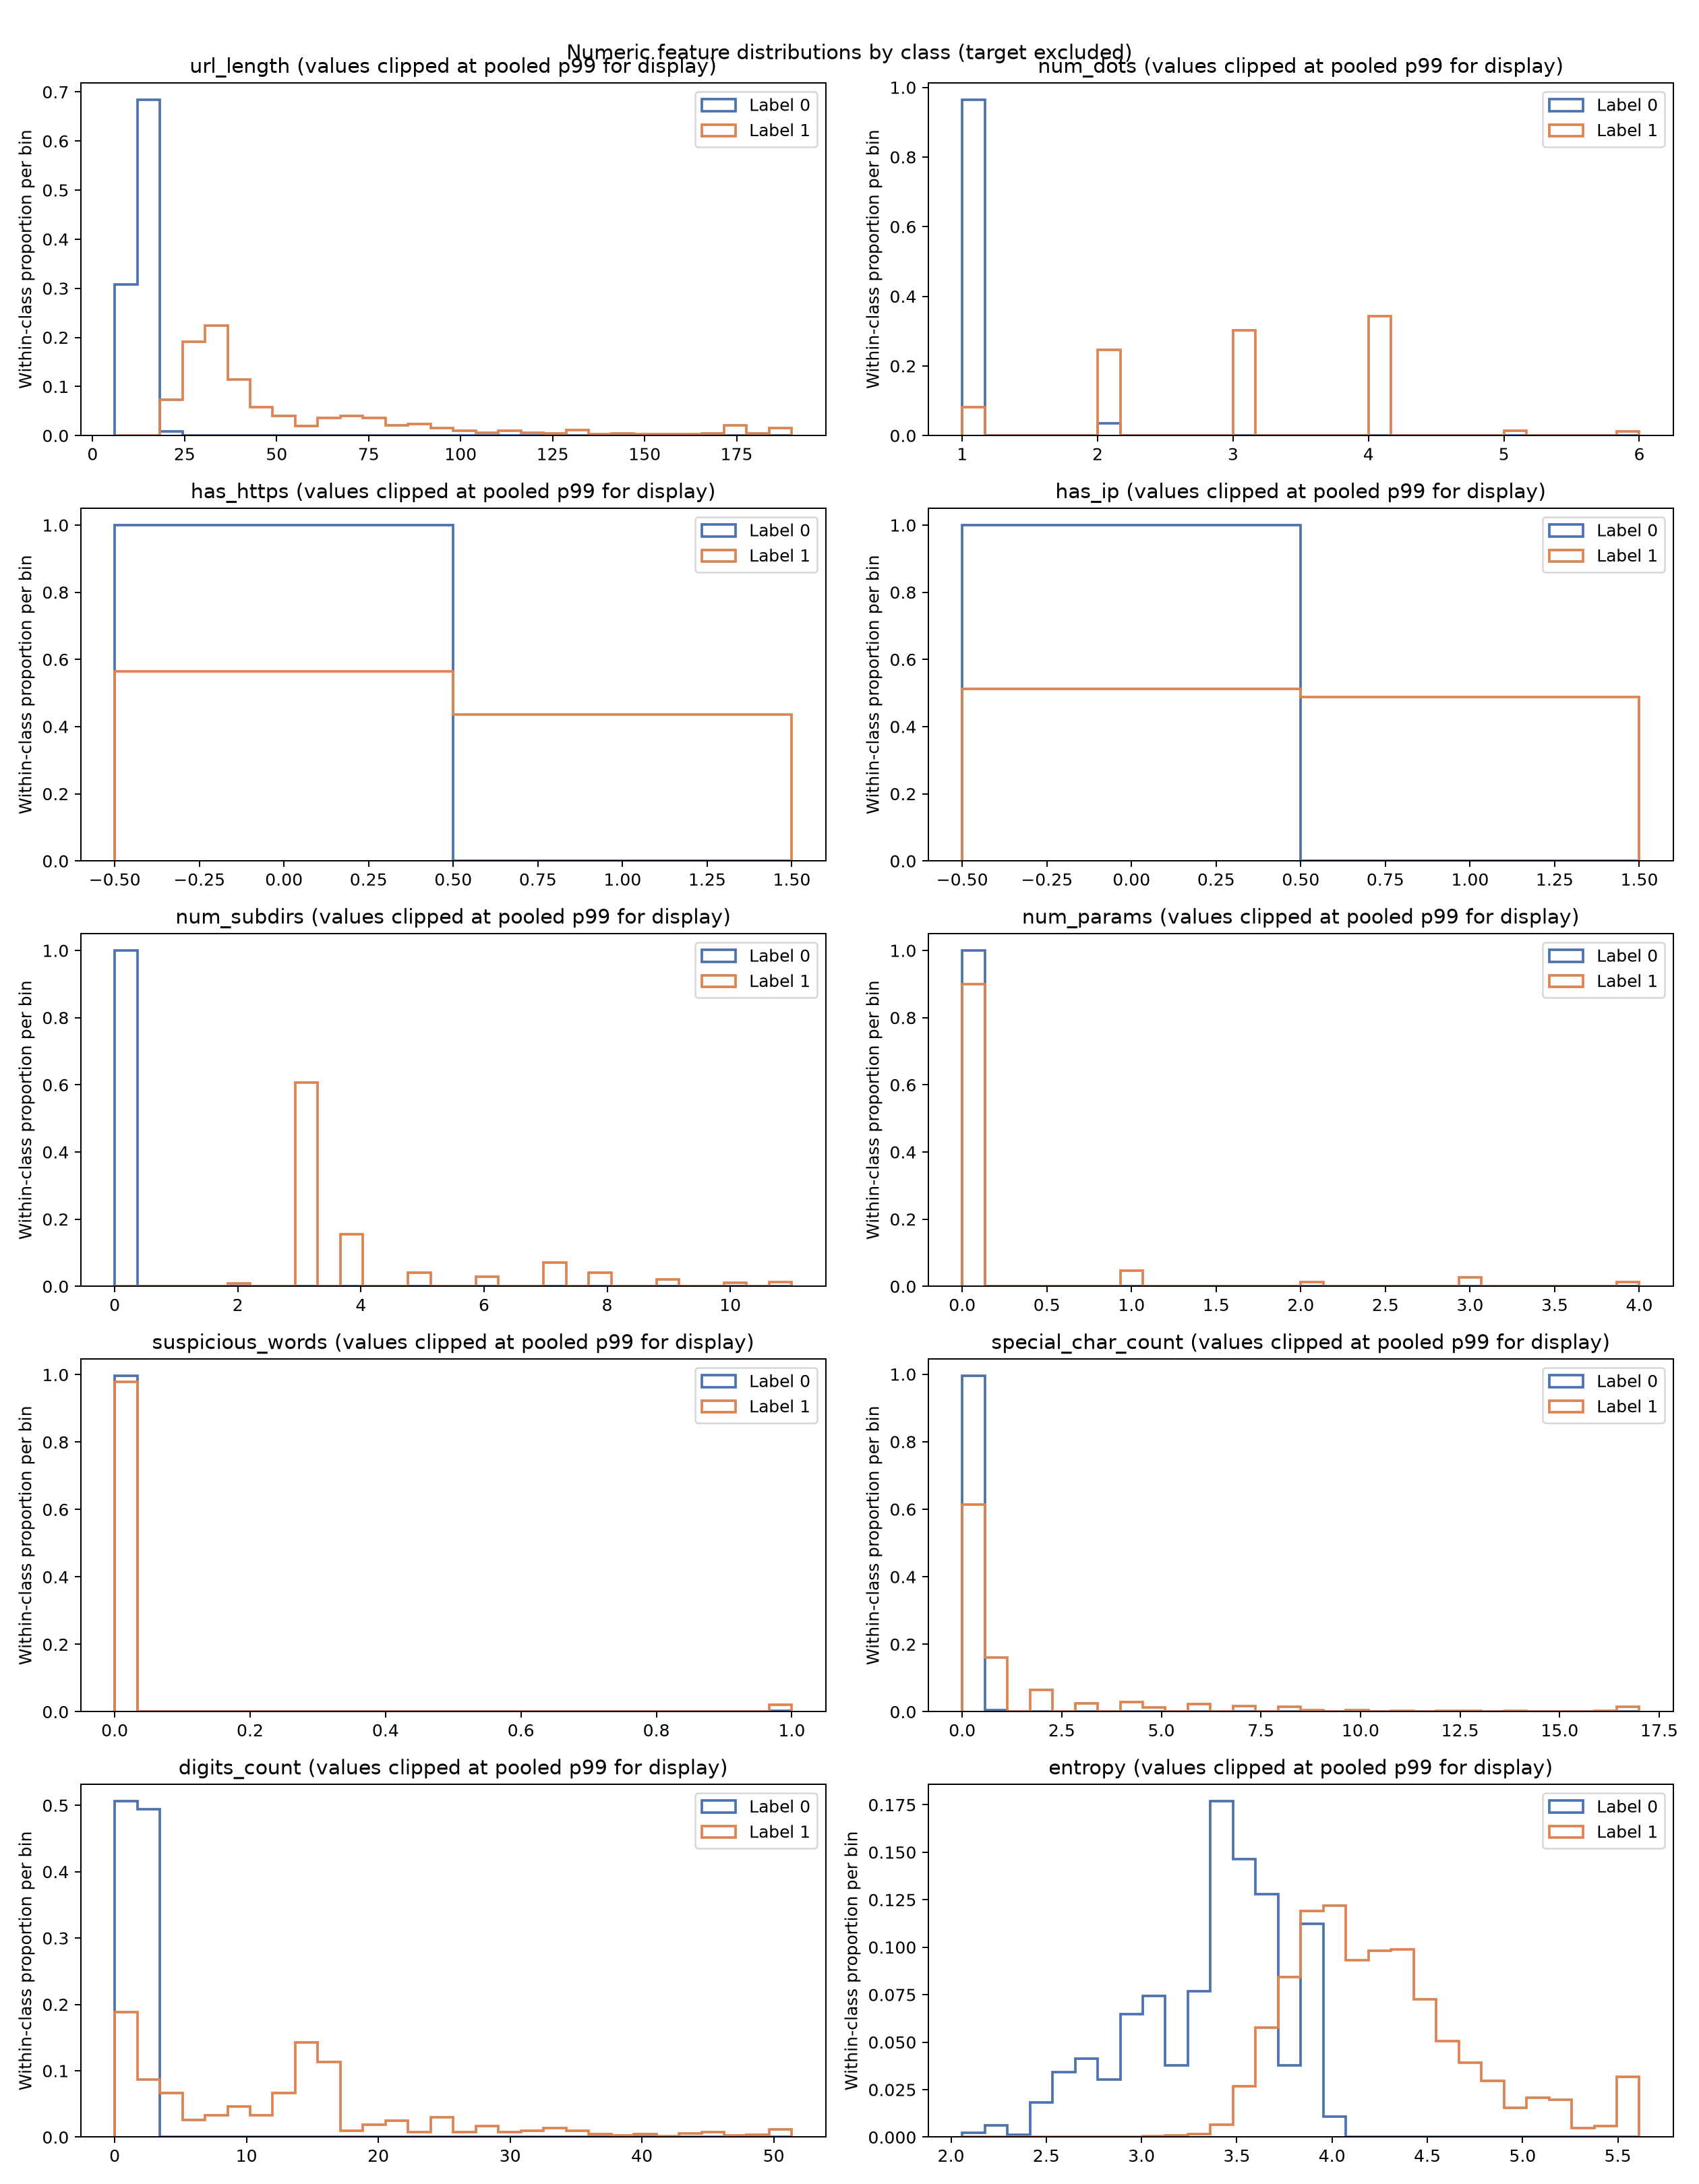

tld_by_label.png


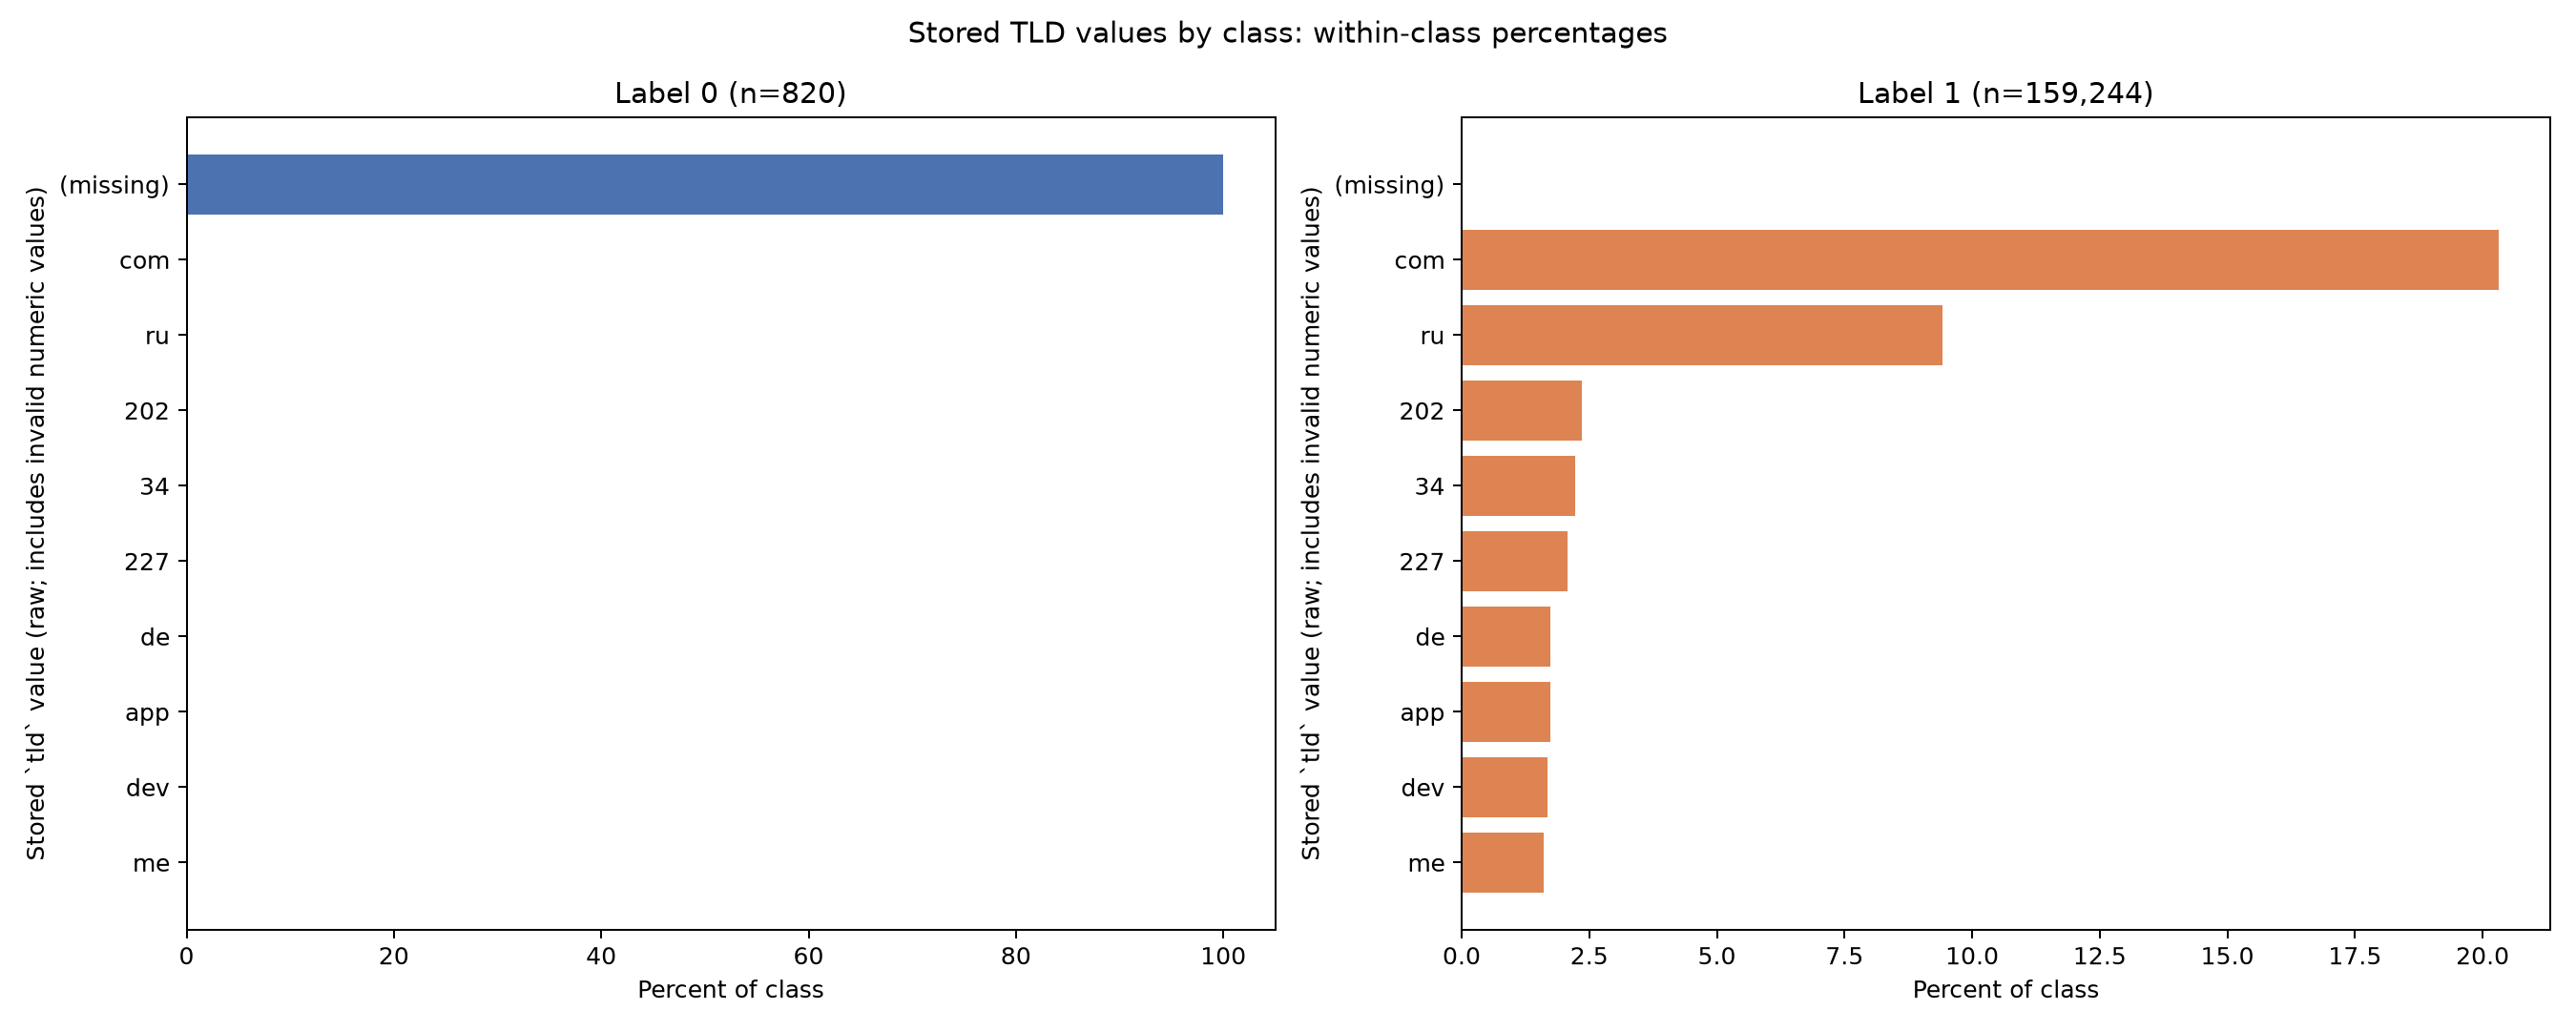

numeric_feature_correlations.png


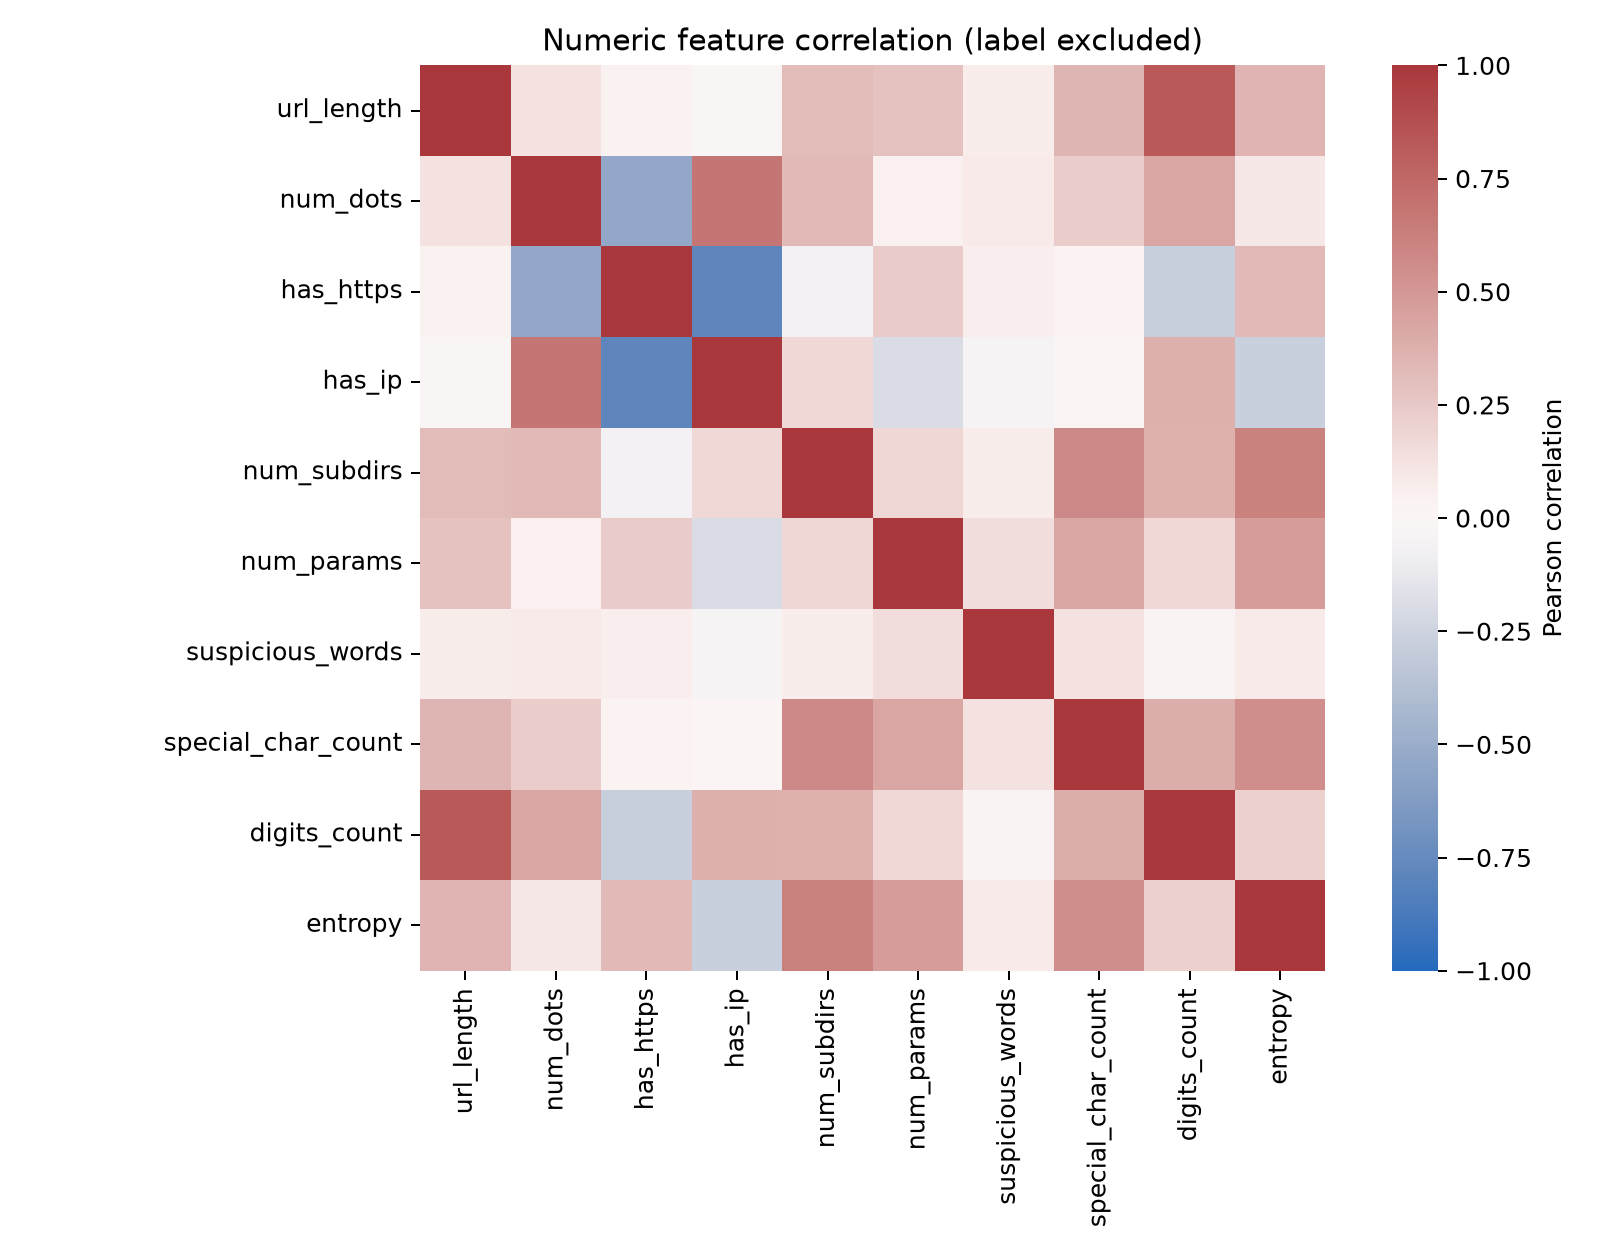

In [6]:
for filename in [
    "label_distribution.png",
    "url_structure_by_label.png",
    "structure_by_label.png",
    "numeric_feature_histograms.png",
    "tld_by_label.png",
    "numeric_feature_correlations.png",
]:
    print(filename)
    display(Image(filename=str(EDA_DIR / "visualizations" / filename)))


## Interpretation and stop conditions

- All label-0 rows are scheme-less, pathless and have `num_subdirs == 0`; all label-1 rows have an HTTP/HTTPS scheme and `num_subdirs >= 2`. The current extractor defines `num_subdirs` as total slash characters, including the two scheme slashes. This is a perfect class-format shortcut in this corpus, not proof of intentional leakage.
- The documented class mapping has no upstream source evidence. Confirm labels, collection dates, source feeds/rankings and annotation method before interpreting model results.
- `tld` has class-dependent missingness and numeric entries; multiple engineered columns do not match the committed extractor.
- Repeated registrable domains and path templates make row-wise random splitting risky. No split or model evaluation was run.
- The detailed evidence, severity assessment and proposed preprocessing plan (not applied) are in `data_quality_and_bias_report.md`.

**Stop here. No cleaning or preprocessing should begin until the unresolved provenance and class-format issues are reviewed and approved.**